<a href="https://colab.research.google.com/github/SantiDrelewicz/prode/blob/main/notebooks/EvaluacionProde.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from sklearn.metrics import mean_poisson_deviance

In [2]:
df = pd.read_parquet("https://github.com/SantiDrelewicz/prode/raw/refs/heads/main/data/partidos_desagregados_lv.parquet")

In [3]:
df

,match_id,league,date,season,team,opponent,gf,ga,xg,xga,...,eds_opp,roll_xg_diff_6,roll_goal_diff_6,diff_elo,desbalance_off,desbalance_def,desbalance_eff_off,desbalance_eff_def,target_goles,is_home
0,5447,Bundesliga,2014-08-22 19:30:00,2014,Bayern Munich,Wolfsburg,2,1,2.570120,1.198420,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2,1
1,5448,Bundesliga,2014-08-23 14:30:00,2014,Hoffenheim,Augsburg,2,0,1.528730,0.280777,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2,1
2,5449,Bundesliga,2014-08-23 14:30:00,2014,Hannover 96,Schalke 04,2,1,1.179790,0.956665,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2,1
3,5450,Bundesliga,2014-08-23 14:30:00,2014,Hertha Berlin,Werder Bremen,2,2,1.755850,1.194530,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2,1
4,5451,Bundesliga,2014-08-23 14:30:00,2014,Eintracht Frankfurt,Freiburg,1,0,1.753310,1.380840,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48933,30215,Serie_A,2026-05-24 18:45:00,2025,Cremonese,Como,1,4,0.977192,2.691100,...,-0.148924,0.165426,0.146699,198.967108,0.779578,-0.372352,-0.236178,-0.266193,4,0
48934,30218,Serie_A,2026-05-24 18:45:00,2025,Lecce,Genoa,1,0,2.213870,0.782331,...,-0.333664,-0.697802,-0.813132,51.965347,-0.352311,0.063970,-0.447331,-0.305904,0,0
48935,30219,Serie_A,2026-05-24 18:45:00,2025,AC Milan,Cagliari,1,2,1.759530,3.436240,...,-0.179252,0.281474,-0.510004,-193.538736,0.439072,-0.850727,-0.287152,-0.361770,2,0
48936,30222,Serie_A,2026-05-24 18:45:00,2025,Torino,Juventus,2,2,0.950066,2.534270,...,-0.021361,0.492407,0.771617,172.398939,1.229653,-1.293839,-0.288429,-0.218932,2,0


In [10]:
# =============================================================================
# 1. CONFIGURACIÓN ORIGINAL
# =============================================================================

FEATURE_SETS = {
    "1_Baseline_Localia": ["is_home"],
    "2_Elo": ["diff_elo", "is_home"],
    "3_Prodegy_Puro": ["xos_team", "xds_opp", "is_home"],
    "4_Prodegy_Con_Eff": ["xos_team", "xds_opp", "eos_team", "is_home"],
    "5_Prodegy_Desbalance": ["desbalance_off", "is_home"],
    "6_Desbalances": [
        "diff_elo", "xos_team", "desbalance_off", "desbalance_eff_off", "is_home",
    ],
    "7_Full_System": [
        "diff_elo", "elo_team", "elo_opp", "xos_team", "xds_team",
        "xos_opp", "xds_opp", "desbalance_off", "desbalance_def",
        "eos_team", "eds_team", "eos_opp", "eds_opp",
        "desbalance_eff_off", "desbalance_eff_def", "is_home",
    ],
}

PARAM_DICT = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_iter": [100, 300],
    "max_depth": [3, 5, 7, None],
    "l2_regularization": [0.0, 0.1, 1.0],
}

N_ITER_RANDOM_SEARCH = 10
MIN_SEASON, MAX_SEASON = 2019, 2025
MIN_TRAIN_SEASONS = 2
RANDOM_STATE = 42

# El primer fold externo, con dos temporadas históricas, tendrá un fold interno.
MIN_TRAIN_SEASONS_INNER = 1

# Reservar 2025 para evaluar al final. Cambiar a None para incluirlo en CV.
TEST_SEASON = MAX_SEASON

In [14]:
"""Validación cruzada anidada temporal para predecir goles de fútbol.

El DataFrame ``df`` ya debe contener las features calculadas y listas para entrenar.
NO se imputan, escalan ni recalculan las variables.

INTRA:
    Para cada liga y temporada externa, ajusta un modelo con temporadas previas
    de esa liga. Su CV interna también usa exclusivamente esa liga.

GLOBAL:
    Para cada temporada externa y conjunto de features, ajusta UN ÚNICO modelo
    usando las temporadas previas de TODAS las ligas. Su CV interna valida cada
    temporada de todas las ligas conjuntamente. El mismo modelo se evalúa
    luego sobre cada liga objetivo, por separado.

La última temporada se puede reservar como test independiente. No se utiliza
para seleccionar hiperparámetros, modelos o estrategias.

Se guardan las predicciones de los folds EXTERNOS y se pueden utilizar para
bootstrap pareado INTRA vs GLOBAL, SIN repetir entrenamientos. El bootstrap
remuestrea partidos completos si existe `match_id`; si no, remuestrea filas.
Los IC resultantes son condicionales a los modelos y temporadas observados.
"""

# =============================================================================
# 2. FOLDS TEMPORALES INTERNOS (PARA AMBAS ESTRATEGIAS)
# =============================================================================

def folds_temporales(df_train: pd.DataFrame, min_train_seasons: int = 1):
    """Devuelve los índices posicionales de CV temporal expansiva.

    Si df_train contiene una sola liga, los folds son INTRA.
    Si contiene todas las ligas, son GLOBAL; en cada fold se valida la
    temporada completa de TODAS las ligas a la vez.

    Ejemplo con 2019, 2020, 2021 y min_train_seasons=1:
        train 2019       -> val 2020
        train 2019-2020  -> val 2021
    """
    if min_train_seasons < 1:
        raise ValueError("min_train_seasons debe ser >= 1.")

    grupos = df_train["season"].to_numpy()
    temporadas = np.sort(pd.unique(grupos))
    splits = []

    for temporada_val in temporadas[min_train_seasons:]:
        idx_train = np.flatnonzero(grupos < temporada_val)
        idx_val = np.flatnonzero(grupos == temporada_val)
        if len(idx_train) and len(idx_val):
            splits.append((idx_train, idx_val))

    if not splits:
        raise ValueError(
            f"No se pudieron construir folds internos: "
            f"{len(temporadas)} temporadas disponibles, "
            f"mínimo de entrenamiento={min_train_seasons}."
        )

    return splits


# =============================================================================
# 3. AJUSTE DE MODELO (CON CV INTERNA SI CORRESPONDE)
# =============================================================================

def entrenar_modelo(
    df_train: pd.DataFrame,
    columnas_features: list[str],
    param_dict: dict,
    *,
    n_iter: int = 10,
    min_train_seasons_inner: int = 1,
    random_state: int = 42,
    n_jobs: int = -1,
):
    """Ajusta un modelo sin observar la temporada externa de validación.

    <= 2 features: PoissonRegressor fijo (sin CV interna).
    > 2 features: HistGradientBoostingRegressor con RandomizedSearchCV temporal.

    Retorna (estimador_entrenado, mejores_params, score_cv_interna, n_folds).
    """
    X_train = df_train[columnas_features]
    y_train = df_train["target_goles"]

    if len(columnas_features) <= 2:
        modelo = PoissonRegressor(max_iter=1000)
        modelo.fit(X_train, y_train)
        return modelo, {"modelo": "PoissonRegressor"}, np.nan, 0

    cv = folds_temporales(
        df_train, min_train_seasons=min_train_seasons_inner
    )
    buscador = RandomizedSearchCV(
        estimator=HistGradientBoostingRegressor(
            loss="poisson",
            early_stopping=False,  # sin partición aleatoria interna adicional
            random_state=random_state,
        ),
        param_distributions=param_dict,
        n_iter=n_iter,
        cv=cv,
        scoring="neg_mean_poisson_deviance",
        n_jobs=n_jobs,
        random_state=random_state,
        refit=True,  # reentrena con TODO df_train, una vez seleccionados los params
        error_score="raise",
    )
    buscador.fit(X_train, y_train)
    return (
        buscador.best_estimator_,
        buscador.best_params_,
        -float(buscador.best_score_),
        len(cv),
    )


# =============================================================================
# 4. EVALUACIÓN EN UNA LIGA (SIN REENTRENAR)
# =============================================================================

def evaluar_en_liga(
    modelo,
    df_val: pd.DataFrame,
    columnas_features: list[str],
) -> tuple[float, np.ndarray]:
    """Devuelve (deviance, predicciones) sin reentrenar el modelo."""
    preds = np.asarray(modelo.predict(df_val[columnas_features]), dtype=float)
    deviance = float(mean_poisson_deviance(df_val["target_goles"], preds))
    return deviance, preds


def guardar_predicciones(
    df_val: pd.DataFrame,
    preds: np.ndarray,
    *,
    liga: str,
    temporada: int,
    nombre_modelo: str,
    estrategia: str,
) -> pd.DataFrame:
    """Preserva alineación exacta INTRA/GLOBAL mediante `_id_fila`."""
    salida = pd.DataFrame({
        "_id_fila": df_val["_id_fila"].to_numpy(),
        "Liga": liga,
        "Temporada_Validacion": temporada,
        "Modelo": nombre_modelo,
        "Estrategia": estrategia,
        "y_true": df_val["target_goles"].to_numpy(),
        "y_pred": preds,
    })
    if "match_id" in df_val.columns:
        salida["match_id"] = df_val["match_id"].to_numpy()
    return salida


# =============================================================================
# 5. NESTED CV TEMPORAL: GLOBAL UNA SOLA VEZ, INTRA POR LIGA
# =============================================================================

def temporal_nested_cv(
    df: pd.DataFrame,
    feature_sets: dict[str, list[str]],
    param_dict: dict,
    *,
    min_season: int | None = None,
    max_season: int | None = None,
    test_season: int | None = None,
    min_train_seasons: int = 2,
    min_train_seasons_inner: int = 1,
    n_iter: int = 10,
    random_state: int = 42,
    n_jobs: int = -1,
    verbose: bool = False,
) -> dict[str, pd.DataFrame]:
    """Compara INTRA y GLOBAL mediante nested CV temporal expansiva.

    El DataFrame se utiliza tal como llega: solo se filtra por temporadas
    para crear desarrollo/test y conjuntos de train/validación.

    Para cada temporada externa:
      1) GLOBAL: ajusta cada modelo UNA vez con todas las ligas anteriores.
         La CV interna valida temporadas completas de TODAS las ligas.
         Evalúa ese mismo modelo en cada liga de la temporada externa.
      2) INTRA: ajusta cada modelo por separado para cada liga, usando
         solamente temporadas anteriores de esa misma liga.

    Los pares liga/temporada externa comparados son idénticos entre estrategias.
    """
    if min_train_seasons_inner < 1:
        raise ValueError("min_train_seasons_inner debe ser >= 1.")
    if min_train_seasons < min_train_seasons_inner + 1:
        raise ValueError(
            "min_train_seasons debe ser al menos min_train_seasons_inner + 1, "
            "para que exista CV interna en el primer fold externo."
        )
    if n_iter < 1:
        raise ValueError("n_iter debe ser >= 1.")
    if not feature_sets:
        raise ValueError("feature_sets no puede estar vacío.")

    requeridas = {"league", "season", "target_goles"}
    requeridas.update(f for cols in feature_sets.values() for f in cols)
    faltantes = requeridas.difference(df.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas en df: {sorted(faltantes)}")
    if df[["league", "season", "target_goles"]].isna().any().any():
        raise ValueError("Hay valores nulos en league, season o target_goles.")
    if (df["target_goles"] < 0).any():
        raise ValueError("target_goles debe ser no negativo para Poisson.")

    # Sin imputación ni transformaciones de features: solo filtramos años.
    datos = df
    if min_season is not None:
        datos = datos.loc[datos["season"] >= min_season]
    if max_season is not None:
        datos = datos.loc[datos["season"] <= max_season]

    if test_season is not None:
        test = datos.loc[datos["season"] == test_season]
        if test.empty:
            raise ValueError(f"No hay partidos para el test_season={test_season}.")
        desarrollo = datos.loc[datos["season"] < test_season]
    else:
        test = datos.iloc[0:0]
        desarrollo = datos

    if desarrollo.empty:
        raise ValueError("No quedaron partidos en el conjunto de desarrollo.")

    # ID técnico único por FILA para emparejar sin ambigüedad las predicciones,
    # incluso si df llegó con el índice duplicado. No se usa como feature.
    desarrollo = desarrollo.copy().reset_index(drop=True)
    desarrollo["_id_fila"] = np.arange(len(desarrollo), dtype=np.int64)

    ligas = sorted(desarrollo["league"].unique())
    por_liga = {
        liga: desarrollo.loc[desarrollo["league"] == liga]
        for liga in ligas
    }

    # Una única lista de pares (temporada, liga) válidos para ambas estrategias.
    # Una liga entra en la evaluación cuando tiene suficiente historia PROPIA.
    plan_validacion = {}
    for temporada in sorted(desarrollo["season"].unique()):
        ligas_validas = []
        for liga, datos_liga in por_liga.items():
            mask_val = datos_liga["season"] == temporada
            n_anteriores = datos_liga.loc[
                datos_liga["season"] < temporada, "season"
            ].nunique()
            if mask_val.any() and n_anteriores >= min_train_seasons:
                ligas_validas.append(liga)
        if ligas_validas:
            plan_validacion[temporada] = ligas_validas

    if not plan_validacion:
        raise ValueError(
            "No hay folds externos disponibles con min_train_seasons="
            f"{min_train_seasons}."
        )

    resultados = []
    predicciones_externas = []

    # BUCLE EXTERNO: TEMPORADAS. GLOBAL NO ESTÁ DENTRO DEL BUCLE DE LIGAS.
    for temporada, ligas_validas in plan_validacion.items():
        df_train_global = desarrollo.loc[desarrollo["season"] < temporada]

        df_validaciones = {
            liga: por_liga[liga].loc[
                por_liga[liga]["season"] == temporada
            ]
            for liga in ligas_validas
        }

        if verbose:
            print(f"\n{'=' * 72}")
            print(f"Temporada {temporada} | Evaluando: {', '.join(ligas_validas)}")

        # ---------------------------------------------------------------------
        # GLOBAL: un ajuste por (temporada, feature_set), reutilizado en ligas.
        # ---------------------------------------------------------------------
        for nombre_modelo, features in feature_sets.items():
            if verbose:
                print(f"GLOBAL | {temporada} | {nombre_modelo} | ajuste único")

            modelo, params, score_int, n_folds_int = entrenar_modelo(
                df_train=df_train_global,
                columnas_features=features,
                param_dict=param_dict,
                n_iter=n_iter,
                min_train_seasons_inner=min_train_seasons_inner,
                random_state=random_state,
                n_jobs=n_jobs,
            )

            for liga, df_val in df_validaciones.items():
                deviance, preds = evaluar_en_liga(modelo, df_val, features)
                predicciones_externas.append(guardar_predicciones(
                    df_val, preds, liga=liga, temporada=temporada,
                    nombre_modelo=nombre_modelo, estrategia="GLOBAL",
                ))
                resultados.append({
                    "Liga": liga,
                    "Temporada_Validacion": temporada,
                    "Modelo": nombre_modelo,
                    "Estrategia": "GLOBAL",
                    "Parametros": params,
                    "Deviance_CV_Interna": score_int,
                    "N_Folds_Internos": n_folds_int,
                    "Deviance": deviance,
                    "N_Train": len(df_train_global),
                    "N_Val": len(df_val),
                })
                if verbose:
                    print(f"    → {liga}: deviance={deviance:.4f}")

        # ---------------------------------------------------------------------
        # INTRA: un ajuste por (temporada, liga, feature_set).
        # ---------------------------------------------------------------------
        for liga, df_val in df_validaciones.items():
            df_train_intra = por_liga[liga].loc[
                por_liga[liga]["season"] < temporada
            ]
            for nombre_modelo, features in feature_sets.items():
                if verbose:
                    print(f"INTRA  | {temporada} | {liga} | {nombre_modelo}")

                modelo, params, score_int, n_folds_int = entrenar_modelo(
                    df_train=df_train_intra,
                    columnas_features=features,
                    param_dict=param_dict,
                    n_iter=n_iter,
                    min_train_seasons_inner=min_train_seasons_inner,
                    random_state=random_state,
                    n_jobs=n_jobs,
                )
                deviance, preds = evaluar_en_liga(modelo, df_val, features)
                predicciones_externas.append(guardar_predicciones(
                    df_val, preds, liga=liga, temporada=temporada,
                    nombre_modelo=nombre_modelo, estrategia="INTRA",
                ))
                resultados.append({
                    "Liga": liga,
                    "Temporada_Validacion": temporada,
                    "Modelo": nombre_modelo,
                    "Estrategia": "INTRA",
                    "Parametros": params,
                    "Deviance_CV_Interna": score_int,
                    "N_Folds_Internos": n_folds_int,
                    "Deviance": deviance,
                    "N_Train": len(df_train_intra),
                    "N_Val": len(df_val),
                })
                if verbose:
                    print(f"    → deviance={deviance:.4f}")

    detalle = (
        pd.DataFrame(resultados)
        .sort_values(["Liga", "Temporada_Validacion", "Modelo", "Estrategia"])
        .reset_index(drop=True)
    )

    # Primero el promedio de temporadas dentro de cada liga; luego el promedio
    # entre ligas. De esta manera cada liga tiene el mismo peso en el resumen.
    por_liga_resumen = (
        detalle.groupby(["Liga", "Modelo", "Estrategia"], as_index=False)
        .agg(
            Deviance_Promedio=("Deviance", "mean"),
            Deviance_STD=("Deviance", "std"),
            N_Temporadas=("Deviance", "size"),
        )
    )
    resumen = (
        por_liga_resumen.groupby(["Modelo", "Estrategia"], as_index=False)
        .agg(
            Deviance_Promedio_Ligas=("Deviance_Promedio", "mean"),
            Deviance_STD_Entre_Ligas=("Deviance_Promedio", "std"),
            N_Ligas=("Liga", "nunique"),
        )
    )
    comparacion = (
        resumen.pivot(
            index="Modelo",
            columns="Estrategia",
            values="Deviance_Promedio_Ligas",
        )
        .rename(columns={"INTRA": "Deviance_INTRA", "GLOBAL": "Deviance_GLOBAL"})
        .reset_index()
    )
    comparacion.columns.name = None
    comparacion["GLOBAL_menos_INTRA"] = (
        comparacion["Deviance_GLOBAL"] - comparacion["Deviance_INTRA"]
    )

    return {
        "detalle": detalle,
        "por_liga": por_liga_resumen,
        "resumen": resumen,
        "comparacion": comparacion,
        "predicciones": pd.concat(predicciones_externas, ignore_index=True),
        "test": test,  # reservado, NO evaluado ni utilizado en la búsqueda
    }

In [15]:
resultados = temporal_nested_cv(
    df=df,
    feature_sets=FEATURE_SETS,
    param_dict=PARAM_DICT,
    min_season=MIN_SEASON,
    max_season=MAX_SEASON,
    test_season=TEST_SEASON,
    min_train_seasons=MIN_TRAIN_SEASONS,
    min_train_seasons_inner=MIN_TRAIN_SEASONS_INNER,
    n_iter=N_ITER_RANDOM_SEARCH,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=True,
)

display(resultados["detalle"])
display(resultados["por_liga"])
display(resultados["resumen"].sort_values("Deviance_Promedio_Ligas"))
display(resultados["comparacion"])


Temporada 2021 | Evaluando: Bundesliga, EPL, La_Liga, Ligue_1, RFPL, Serie_A
GLOBAL | 2021 | 1_Baseline_Localia | ajuste único
    → Bundesliga: deviance=1.3032
    → EPL: deviance=1.3326
    → La_Liga: deviance=1.2971
    → Ligue_1: deviance=1.2295
    → RFPL: deviance=1.1317
    → Serie_A: deviance=1.1931
GLOBAL | 2021 | 2_Elo | ajuste único
    → Bundesliga: deviance=1.1873
    → EPL: deviance=1.1511
    → La_Liga: deviance=1.2143
    → Ligue_1: deviance=1.1524
    → RFPL: deviance=1.0818
    → Serie_A: deviance=1.0636
GLOBAL | 2021 | 3_Prodegy_Puro | ajuste único
    → Bundesliga: deviance=1.1452
    → EPL: deviance=1.1355
    → La_Liga: deviance=1.1921
    → Ligue_1: deviance=1.1232
    → RFPL: deviance=1.0552
    → Serie_A: deviance=1.0661
GLOBAL | 2021 | 4_Prodegy_Con_Eff | ajuste único
    → Bundesliga: deviance=1.1448
    → EPL: deviance=1.1365
    → La_Liga: deviance=1.1922
    → Ligue_1: deviance=1.1232
    → RFPL: deviance=1.0550
    → Serie_A: deviance=1.0659
GLOBAL | 202

,Liga,Temporada_Validacion,Modelo,Estrategia,Parametros,Deviance_CV_Interna,N_Folds_Internos,Deviance,N_Train,N_Val
0,Bundesliga,2021,1_Baseline_Localia,GLOBAL,{'modelo': 'PoissonRegressor'},NaN,0,1.303157,8062,612
1,Bundesliga,2021,1_Baseline_Localia,INTRA,{'modelo': 'PoissonRegressor'},NaN,0,1.282436,1224,612
2,Bundesliga,2021,2_Elo,GLOBAL,{'modelo': 'PoissonRegressor'},NaN,0,1.187325,8062,612
3,Bundesliga,2021,2_Elo,INTRA,{'modelo': 'PoissonRegressor'},NaN,0,1.162573,1224,612
4,Bundesliga,2021,3_Prodegy_Puro,GLOBAL,"{'max_iter': 300, 'max_depth': 3, 'learning_ra...",1.126072,1,1.145200,8062,612
...,...,...,...,...,...,...,...,...,...,...
331,Serie_A,2024,5_Prodegy_Desbalance,INTRA,{'modelo': 'PoissonRegressor'},NaN,0,1.170552,3800,760
332,Serie_A,2024,6_Desbalances,GLOBAL,"{'max_iter': 300, 'max_depth': 3, 'learning_ra...",1.117531,4,1.041848,20310,760
333,Serie_A,2024,6_Desbalances,INTRA,"{'max_iter': 300, 'max_depth': 3, 'learning_ra...",1.083163,4,1.042777,3800,760
334,Serie_A,2024,7_Full_System,GLOBAL,"{'max_iter': 300, 'max_depth': 3, 'learning_ra...",1.114451,4,1.038214,20310,760


,Liga,Modelo,Estrategia,Deviance_Promedio,Deviance_STD,N_Temporadas
0,Bundesliga,1_Baseline_Localia,GLOBAL,1.316018,0.027799,4
1,Bundesliga,1_Baseline_Localia,INTRA,1.290667,0.031791,4
2,Bundesliga,2_Elo,GLOBAL,1.207028,0.050127,4
3,Bundesliga,2_Elo,INTRA,1.179905,0.056678,4
4,Bundesliga,3_Prodegy_Puro,GLOBAL,1.155007,0.059455,4
...,...,...,...,...,...,...
79,Serie_A,5_Prodegy_Desbalance,INTRA,1.187661,0.012613,4
80,Serie_A,6_Desbalances,GLOBAL,1.057080,0.014038,4
81,Serie_A,6_Desbalances,INTRA,1.070709,0.022459,4
82,Serie_A,7_Full_System,GLOBAL,1.052394,0.014568,4


,Modelo,Estrategia,Deviance_Promedio_Ligas,Deviance_STD_Entre_Ligas,N_Ligas
12,7_Full_System,GLOBAL,1.105260,0.035894,6
6,4_Prodegy_Con_Eff,GLOBAL,1.108007,0.034456,6
4,3_Prodegy_Puro,GLOBAL,1.108452,0.034419,6
10,6_Desbalances,GLOBAL,1.109655,0.035679,6
5,3_Prodegy_Puro,INTRA,1.119339,0.031278,6
11,6_Desbalances,INTRA,1.120739,0.034657,6
7,4_Prodegy_Con_Eff,INTRA,1.121145,0.033913,6
13,7_Full_System,INTRA,1.126015,0.035206,6
3,2_Elo,INTRA,1.129093,0.036910,6
2,2_Elo,GLOBAL,1.132140,0.046271,6


,Modelo,Deviance_GLOBAL,Deviance_INTRA,GLOBAL_menos_INTRA
0,1_Baseline_Localia,1.241426,1.238722,0.002703
1,2_Elo,1.132140,1.129093,0.003048
2,3_Prodegy_Puro,1.108452,1.119339,-0.010887
3,4_Prodegy_Con_Eff,1.108007,1.121145,-0.013137
4,5_Prodegy_Desbalance,1.227633,1.225040,0.002593
5,6_Desbalances,1.109655,1.120739,-0.011084
6,7_Full_System,1.105260,1.126015,-0.020755


,Liga,Temporada_Validacion,Modelo,N_Filas,N_Partidos_o_Bloques,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,Bundesliga,2021,1_Baseline_Localia,612,306,1.282436,1.303157,0.020721,1.157845,1.415213,1.175512,1.444822,-0.003625,0.043822,0.012234,False
1,Bundesliga,2021,2_Elo,612,306,1.162573,1.187325,0.024752,1.055468,1.274158,1.080900,1.303372,-0.000977,0.050280,0.013275,False
2,Bundesliga,2021,3_Prodegy_Puro,612,306,1.153218,1.145200,-0.008017,1.044588,1.266831,1.036709,1.259551,-0.028975,0.013430,0.010761,False
3,Bundesliga,2021,4_Prodegy_Con_Eff,612,306,1.168105,1.144808,-0.023297,1.056318,1.286079,1.036955,1.259198,-0.045649,-0.001397,0.011305,True
4,Bundesliga,2021,5_Prodegy_Desbalance,612,306,1.226320,1.258252,0.031932,1.106761,1.352799,1.133572,1.393639,0.007134,0.057275,0.012915,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,Serie_A,2024,3_Prodegy_Puro,760,380,1.046600,1.043035,-0.003565,0.955129,1.134478,0.954669,1.130078,-0.013709,0.007553,0.005572,False
164,Serie_A,2024,4_Prodegy_Con_Eff,760,380,1.045429,1.043306,-0.002123,0.956636,1.131642,0.955768,1.129927,-0.013360,0.009219,0.005761,False
165,Serie_A,2024,5_Prodegy_Desbalance,760,380,1.170552,1.163029,-0.007523,1.069160,1.271051,1.063118,1.261791,-0.013197,-0.002101,0.002801,True
166,Serie_A,2024,6_Desbalances,760,380,1.042777,1.041848,-0.000929,0.952927,1.129817,0.953614,1.129272,-0.013825,0.011476,0.006340,False


,Liga,Modelo,N_Temporadas,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,Bundesliga,1_Baseline_Localia,4,1.290667,1.316018,0.025351,1.227233,1.356206,1.250412,1.384289,0.013195,0.037359,0.006138,True
1,Bundesliga,2_Elo,4,1.179905,1.207028,0.027123,1.122669,1.236442,1.150683,1.263353,0.013967,0.040000,0.006682,True
2,Bundesliga,3_Prodegy_Puro,4,1.154036,1.155007,0.000971,1.099237,1.208367,1.101567,1.211247,-0.009418,0.011765,0.005367,False
3,Bundesliga,4_Prodegy_Con_Eff,4,1.158813,1.155965,-0.002849,1.102858,1.214219,1.102634,1.211816,-0.013438,0.008234,0.005557,False
4,Bundesliga,5_Prodegy_Desbalance,4,1.258256,1.286832,0.028576,1.197160,1.322155,1.222690,1.351698,0.015967,0.041430,0.006580,True
5,Bundesliga,6_Desbalances,4,1.162100,1.164527,0.002427,1.109111,1.216356,1.110696,1.218466,-0.009790,0.014346,0.006261,False
6,Bundesliga,7_Full_System,4,1.160405,1.160702,0.000297,1.105662,1.215910,1.107896,1.215825,-0.012675,0.013088,0.006684,False
7,EPL,1_Baseline_Localia,4,1.282055,1.280516,-0.001538,1.225813,1.338538,1.225020,1.336808,-0.003188,0.000080,0.000842,False
8,EPL,2_Elo,4,1.146145,1.141953,-0.004192,1.096651,1.196017,1.092149,1.191654,-0.006325,-0.002043,0.001100,True
9,EPL,3_Prodegy_Puro,4,1.141901,1.121095,-0.020805,1.092594,1.190398,1.072428,1.169137,-0.030165,-0.010657,0.004832,True


,Modelo,N_Ligas,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,7_Full_System,6,1.126015,1.105260,-0.020755,1.105750,1.145838,1.084591,1.124827,-0.025525,-0.016173,0.002426,True
1,4_Prodegy_Con_Eff,6,1.121145,1.108007,-0.013137,1.100559,1.141039,1.087225,1.127594,-0.017599,-0.008710,0.002244,True
2,6_Desbalances,6,1.120739,1.109655,-0.011084,1.100037,1.140163,1.089261,1.129506,-0.015598,-0.006519,0.002302,True
3,3_Prodegy_Puro,6,1.119339,1.108452,-0.010887,1.098916,1.138925,1.087598,1.128182,-0.015164,-0.006665,0.002179,True
4,5_Prodegy_Desbalance,6,1.225040,1.227633,0.002593,1.201859,1.247190,1.204943,1.249629,-0.000311,0.005556,0.001501,False
5,1_Baseline_Localia,6,1.238722,1.241426,0.002703,1.215687,1.261499,1.218109,1.263994,-0.000250,0.005599,0.001473,False
6,2_Elo,6,1.129093,1.132140,0.003048,1.108491,1.149091,1.110768,1.152073,0.000094,0.005980,0.001513,True


In [17]:

# =============================================================================
# 6. BOOTSTRAP PAREADO: INTRA VS GLOBAL SIN VOLVER A ENTRENAR
# =============================================================================

def _poisson_deviance_por_fila(y_true, y_pred):
    """Contribución individual a mean_poisson_deviance (scikit-learn)."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if np.any(y_true < 0) or np.any(y_pred <= 0):
        raise ValueError("Poisson requiere y_true >= 0 e y_pred > 0.")
    # Para y=0, la convención matemática es 0 * log(0/mu) = 0.
    with np.errstate(divide="ignore", invalid="ignore"):
        termino = np.where(y_true > 0, y_true * np.log(y_true / y_pred), 0.0)
    return 2 * (termino - y_true + y_pred)


def _resamples_pareados(loss_intra, loss_global, bloques, B, seed):
    """Bootstrap sobre bloques; respeta ponderación por fila en la deviance."""
    rng = np.random.default_rng(seed)
    n_bloques = int(bloques.max()) + 1
    tamanos = np.bincount(bloques, minlength=n_bloques)
    sum_intra = np.bincount(bloques, weights=loss_intra, minlength=n_bloques)
    sum_global = np.bincount(bloques, weights=loss_global, minlength=n_bloques)

    out_intra = np.empty(B)
    out_global = np.empty(B)
    # Procesar de a lotes para limitar RAM con datasets grandes.
    tam_lote = max(1, min(B, 200_000 // n_bloques))
    for inicio in range(0, B, tam_lote):
        fin = min(B, inicio + tam_lote)
        sample = rng.integers(n_bloques, size=(fin - inicio, n_bloques))
        denominador = tamanos[sample].sum(axis=1)
        out_intra[inicio:fin] = sum_intra[sample].sum(axis=1) / denominador
        out_global[inicio:fin] = sum_global[sample].sum(axis=1) / denominador

    return out_intra, out_global


def analizar_bootstrap_pareado(
    predicciones: pd.DataFrame,
    *,
    B: int = 2000,
    confianza: float = 0.95,
    random_state: int = 42,
    agrupar_por_partido: bool = True,
) -> dict[str, pd.DataFrame]:
    """IC percentiles de deviance y diferencia GLOBAL-INTRA, sin refit.

    Se remuestrean las mismas instancias para ambas estrategias (pareado).
    Si existe `match_id` y agrupar_por_partido=True, se remuestrean partidos
    completos; útil cuando el dataset tiene una fila por equipo/partido.

    Agregación replica la CV: primero media de folds externos por liga y
    después media entre ligas, dándole idéntico peso a cada liga.

    IMPORTANTE: bootstrap condicional a modelos y temporadas observadas.
    NO cuantifica la incertidumbre entre futuras temporadas ni por reentrenar.
    Tampoco corrige selección entre múltiples modelos.
    """
    if B < 2:
        raise ValueError("B debe ser >= 2.")
    if not 0 < confianza < 1:
        raise ValueError("confianza debe estar entre 0 y 1.")
    cols = ["Liga", "Temporada_Validacion", "Modelo", "_id_fila"]
    obligatorias = set(cols + ["Estrategia", "y_true", "y_pred"])
    if not obligatorias.issubset(predicciones.columns):
        raise ValueError(f"Faltan columnas: {sorted(obligatorias - set(predicciones.columns))}")
    if predicciones[cols + ["Estrategia"]].duplicated().any():
        raise ValueError("Hay predicciones duplicadas para una misma fila/estrategia.")
    if not predicciones["Estrategia"].isin(["INTRA", "GLOBAL"]).all():
        raise ValueError("Las estrategias deben ser exclusivamente INTRA o GLOBAL.")

    intra = predicciones.loc[predicciones["Estrategia"] == "INTRA"]
    global_ = predicciones.loc[predicciones["Estrategia"] == "GLOBAL"]
    if len(intra) != len(global_):
        raise ValueError("INTRA y GLOBAL deben tener idéntica cantidad de filas.")
    if len(intra) == 0:
        raise ValueError("No se recibieron predicciones de ambas estrategias.")
    extra = ["match_id"] if "match_id" in predicciones.columns else []
    pares = intra[cols + extra + ["y_true", "y_pred"]].merge(
        global_[cols + extra + ["y_true", "y_pred"]],
        on=cols,
        how="inner",
        validate="one_to_one",
        suffixes=("_INTRA", "_GLOBAL"),
    )
    if len(pares) != len(intra):
        raise ValueError("Faltan pares INTRA/GLOBAL para algunos partidos.")
    if not np.array_equal(pares["y_true_INTRA"].to_numpy(),
                          pares["y_true_GLOBAL"].to_numpy()):
        raise ValueError("Las estrategias no comparten exactamente los targets.")
    usar_partido = agrupar_por_partido and ("match_id" in predicciones.columns)
    if usar_partido:
        if pares[["match_id_INTRA", "match_id_GLOBAL"]].isna().any().any():
            raise ValueError("Hay match_id faltantes. Para bootstrap por partido debe estar completo.")
        if not np.array_equal(pares["match_id_INTRA"].to_numpy(),
                              pares["match_id_GLOBAL"].to_numpy()):
            raise ValueError("Los match_id de INTRA y GLOBAL no coinciden.")

    alpha = (1 - confianza) / 2
    percentiles = [100 * alpha, 100 * (1 - alpha)]

    def resumen_ci(base, arr):
        """Produce las tres métricas y los IC sobre una réplica Bx2."""
        bi, bg = arr
        result = {
            "Deviance_INTRA": float(base[0]),
            "Deviance_GLOBAL": float(base[1]),
            "GLOBAL_menos_INTRA": float(base[1] - base[0]),
        }
        for nombre, boot in [
            ("Deviance_INTRA", bi),
            ("Deviance_GLOBAL", bg),
            ("GLOBAL_menos_INTRA", bg - bi),
        ]:
            inf, sup = np.percentile(boot, percentiles)
            result[f"{nombre}_IC_inf"] = float(inf)
            result[f"{nombre}_IC_sup"] = float(sup)
        result["Diferencia_STD_boot"] = float((bg - bi).std(ddof=1))
        result["Diferencia_IC_excluye_0"] = bool(
            result["GLOBAL_menos_INTRA_IC_inf"] > 0
            or result["GLOBAL_menos_INTRA_IC_sup"] < 0
        )
        return result

    folds = []
    # Keys: (liga, temporada, modelo) -> (B valores intra, B valores global)
    boots_por_fold = {}
    bases_por_fold = {}
    # Misma secuencia de resampleos para todos los modelos de una liga-temporada.
    # Esto permite también realizar comparaciones entre modelos posteriormente.
    rng_maestro = np.random.default_rng(random_state)
    semillas_fold = {
        (liga, temp): int(rng_maestro.integers(0, 2**32))
        for liga, temp in pares[["Liga", "Temporada_Validacion"]]
        .drop_duplicates().itertuples(index=False, name=None)
    }

    for (liga, temp, modelo), fold in pares.groupby(
        ["Liga", "Temporada_Validacion", "Modelo"], sort=True
    ):
        fold = fold.sort_values("_id_fila")
        y = fold["y_true_INTRA"].to_numpy(dtype=float)
        li = _poisson_deviance_por_fila(y, fold["y_pred_INTRA"].to_numpy())
        lg = _poisson_deviance_por_fila(y, fold["y_pred_GLOBAL"].to_numpy())
        if usar_partido:
            # factorize asigna un entero por partido, manteniendo dos perspectivas
            # del mismo encuentro en un único bloque.
            bloques = pd.factorize(fold["match_id_INTRA"], sort=False)[0]
        else:
            bloques = np.arange(len(fold))
        boot_i, boot_g = _resamples_pareados(
            li, lg, bloques, B, semillas_fold[(liga, temp)]
        )
        k = (liga, temp, modelo)
        boots_por_fold[k] = (boot_i, boot_g)
        bases_por_fold[k] = (li.mean(), lg.mean())
        folds.append({
            "Liga": liga,
            "Temporada_Validacion": temp,
            "Modelo": modelo,
            "N_Filas": len(fold),
            "N_Partidos_o_Bloques": len(np.unique(bloques)),
            **resumen_ci(bases_por_fold[k], (boot_i, boot_g)),
        })

    bootstrap_por_fold = pd.DataFrame(folds).sort_values(
        ["Liga", "Temporada_Validacion", "Modelo"]
    ).reset_index(drop=True)

    grupos_liga = {}
    tabla_por_liga = []
    for (liga, modelo), sub in bootstrap_por_fold.groupby(["Liga", "Modelo"], sort=True):
        keys = [(liga, temp, modelo) for temp in sub["Temporada_Validacion"]]
        bi = np.mean([boots_por_fold[k][0] for k in keys], axis=0)
        bg = np.mean([boots_por_fold[k][1] for k in keys], axis=0)
        base_i = np.mean([bases_por_fold[k][0] for k in keys])
        base_g = np.mean([bases_por_fold[k][1] for k in keys])
        grupos_liga[(liga, modelo)] = ((bi, bg), (base_i, base_g))
        tabla_por_liga.append({
            "Liga": liga,
            "Modelo": modelo,
            "N_Temporadas": len(keys),
            **resumen_ci((base_i, base_g), (bi, bg)),
        })
    bootstrap_por_liga = pd.DataFrame(tabla_por_liga).sort_values(
        ["Liga", "Modelo"]
    ).reset_index(drop=True)

    tabla_final = []
    for modelo, sub in bootstrap_por_liga.groupby("Modelo", sort=True):
        keys = [(liga, modelo) for liga in sub["Liga"]]
        bi = np.mean([grupos_liga[k][0][0] for k in keys], axis=0)
        bg = np.mean([grupos_liga[k][0][1] for k in keys], axis=0)
        base_i = np.mean([grupos_liga[k][1][0] for k in keys])
        base_g = np.mean([grupos_liga[k][1][1] for k in keys])
        tabla_final.append({
            "Modelo": modelo,
            "N_Ligas": len(keys),
            **resumen_ci((base_i, base_g), (bi, bg)),
        })
    bootstrap_resumen = pd.DataFrame(tabla_final).sort_values(
        "GLOBAL_menos_INTRA"
    ).reset_index(drop=True)

    return {
        "por_fold": bootstrap_por_fold,
        "por_liga": bootstrap_por_liga,
        "resumen": bootstrap_resumen,
    }


In [18]:
# Bootstrap pareado a partir de predicciones OOF EXTERNAS, sin refit:
bootstrap = analizar_bootstrap_pareado(
    resultados["predicciones"],
    B=2000,
    confianza=0.95,
    random_state=RANDOM_STATE,
    agrupar_por_partido=True,  # usa match_id si existe; si no, filas
)
display(bootstrap["por_fold"])
display(bootstrap["por_liga"])
display(bootstrap["resumen"])

,Liga,Temporada_Validacion,Modelo,N_Filas,N_Partidos_o_Bloques,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,Bundesliga,2021,1_Baseline_Localia,612,306,1.282436,1.303157,0.020721,1.157845,1.415213,1.175512,1.444822,-0.003625,0.043822,0.012234,False
1,Bundesliga,2021,2_Elo,612,306,1.162573,1.187325,0.024752,1.055468,1.274158,1.080900,1.303372,-0.000977,0.050280,0.013275,False
2,Bundesliga,2021,3_Prodegy_Puro,612,306,1.153218,1.145200,-0.008017,1.044588,1.266831,1.036709,1.259551,-0.028975,0.013430,0.010761,False
3,Bundesliga,2021,4_Prodegy_Con_Eff,612,306,1.168105,1.144808,-0.023297,1.056318,1.286079,1.036955,1.259198,-0.045649,-0.001397,0.011305,True
4,Bundesliga,2021,5_Prodegy_Desbalance,612,306,1.226320,1.258252,0.031932,1.106761,1.352799,1.133572,1.393639,0.007134,0.057275,0.012915,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,Serie_A,2024,3_Prodegy_Puro,760,380,1.046600,1.043035,-0.003565,0.955129,1.134478,0.954669,1.130078,-0.013709,0.007553,0.005572,False
164,Serie_A,2024,4_Prodegy_Con_Eff,760,380,1.045429,1.043306,-0.002123,0.956636,1.131642,0.955768,1.129927,-0.013360,0.009219,0.005761,False
165,Serie_A,2024,5_Prodegy_Desbalance,760,380,1.170552,1.163029,-0.007523,1.069160,1.271051,1.063118,1.261791,-0.013197,-0.002101,0.002801,True
166,Serie_A,2024,6_Desbalances,760,380,1.042777,1.041848,-0.000929,0.952927,1.129817,0.953614,1.129272,-0.013825,0.011476,0.006340,False


,Liga,Modelo,N_Temporadas,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,Bundesliga,1_Baseline_Localia,4,1.290667,1.316018,0.025351,1.227233,1.356206,1.250412,1.384289,0.013195,0.037359,0.006138,True
1,Bundesliga,2_Elo,4,1.179905,1.207028,0.027123,1.122669,1.236442,1.150683,1.263353,0.013967,0.040000,0.006682,True
2,Bundesliga,3_Prodegy_Puro,4,1.154036,1.155007,0.000971,1.099237,1.208367,1.101567,1.211247,-0.009418,0.011765,0.005367,False
3,Bundesliga,4_Prodegy_Con_Eff,4,1.158813,1.155965,-0.002849,1.102858,1.214219,1.102634,1.211816,-0.013438,0.008234,0.005557,False
4,Bundesliga,5_Prodegy_Desbalance,4,1.258256,1.286832,0.028576,1.197160,1.322155,1.222690,1.351698,0.015967,0.041430,0.006580,True
5,Bundesliga,6_Desbalances,4,1.162100,1.164527,0.002427,1.109111,1.216356,1.110696,1.218466,-0.009790,0.014346,0.006261,False
6,Bundesliga,7_Full_System,4,1.160405,1.160702,0.000297,1.105662,1.215910,1.107896,1.215825,-0.012675,0.013088,0.006684,False
7,EPL,1_Baseline_Localia,4,1.282055,1.280516,-0.001538,1.225813,1.338538,1.225020,1.336808,-0.003188,0.000080,0.000842,False
8,EPL,2_Elo,4,1.146145,1.141953,-0.004192,1.096651,1.196017,1.092149,1.191654,-0.006325,-0.002043,0.001100,True
9,EPL,3_Prodegy_Puro,4,1.141901,1.121095,-0.020805,1.092594,1.190398,1.072428,1.169137,-0.030165,-0.010657,0.004832,True


,Modelo,N_Ligas,Deviance_INTRA,Deviance_GLOBAL,GLOBAL_menos_INTRA,Deviance_INTRA_IC_inf,Deviance_INTRA_IC_sup,Deviance_GLOBAL_IC_inf,Deviance_GLOBAL_IC_sup,GLOBAL_menos_INTRA_IC_inf,GLOBAL_menos_INTRA_IC_sup,Diferencia_STD_boot,Diferencia_IC_excluye_0
0,7_Full_System,6,1.126015,1.105260,-0.020755,1.105750,1.145838,1.084591,1.124827,-0.025525,-0.016173,0.002426,True
1,4_Prodegy_Con_Eff,6,1.121145,1.108007,-0.013137,1.100559,1.141039,1.087225,1.127594,-0.017599,-0.008710,0.002244,True
2,6_Desbalances,6,1.120739,1.109655,-0.011084,1.100037,1.140163,1.089261,1.129506,-0.015598,-0.006519,0.002302,True
3,3_Prodegy_Puro,6,1.119339,1.108452,-0.010887,1.098916,1.138925,1.087598,1.128182,-0.015164,-0.006665,0.002179,True
4,5_Prodegy_Desbalance,6,1.225040,1.227633,0.002593,1.201859,1.247190,1.204943,1.249629,-0.000311,0.005556,0.001501,False
5,1_Baseline_Localia,6,1.238722,1.241426,0.002703,1.215687,1.261499,1.218109,1.263994,-0.000250,0.005599,0.001473,False
6,2_Elo,6,1.129093,1.132140,0.003048,1.108491,1.149091,1.110768,1.152073,0.000094,0.005980,0.001513,True


In [19]:
"""Graficos y comparaciones estadisticas para la CV temporal de futbol.

Usar DESPUES de temporal_nested_cv y analizar_bootstrap_pareado.
No vuelve a entrenar modelos. Requiere los dataframes de resultados.

Los intervalos y p-values bootstrap son condicionales a los folds/modelos
observados y NO incorporan variabilidad de nuevas temporadas o reentrenamientos.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def _perdida_poisson_por_fila(y, pred):
    """Contribucion individual a mean_poisson_deviance (sin dividir por n)."""
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    if np.any(~np.isfinite(y)) or np.any(~np.isfinite(pred)):
        raise ValueError("Targets y predicciones deben ser finitos.")
    if np.any(y < 0) or np.any(pred <= 0):
        raise ValueError("Poisson requiere y_true >= 0 y y_pred > 0.")
    with np.errstate(divide="ignore", invalid="ignore"):
        term = np.where(y > 0, y * np.log(y / pred), 0.0)
    return 2 * (term - y + pred)


def _holm(p_values):
    """Correccion de Holm-Bonferroni (FWER), sin nuevas dependencias."""
    p = np.asarray(p_values, dtype=float)
    if np.any(~np.isfinite(p)) or np.any((p < 0) | (p > 1)):
        raise ValueError("Los p-values deben estar entre 0 y 1.")
    orden = np.argsort(p)
    m = len(p)
    ajustados = np.maximum.accumulate(p[orden] * (m - np.arange(m)))
    out = np.empty_like(p)
    out[orden] = np.minimum(ajustados, 1.0)
    return out


def _bootstrap_multimodelo_fold(sub, modelos, B, semilla, agrupar_por_partido):
    """B x M de deviances, con LOS MISMOS remuestreos para todos los modelos."""
    claves = ["Modelo", "_id_fila"]
    if sub.duplicated(claves).any():
        raise ValueError("Predicciones duplicadas por modelo y _id_fila.")
    if (sub.groupby("_id_fila")["y_true"].nunique() != 1).any():
        raise ValueError("Targets inconsistentes entre modelos del mismo partido.")

    preds = sub.pivot(index="_id_fila", columns="Modelo", values="y_pred")
    preds = preds.reindex(columns=modelos).sort_index()
    if preds.isna().any().any() or set(sub['Modelo']) != set(modelos):
        raise ValueError("Cada modelo debe predecir exactamente las mismas filas del fold.")

    sub_base = sub.drop_duplicates("_id_fila").set_index("_id_fila").loc[preds.index]
    if len(sub) != len(modelos) * len(preds):
        raise ValueError("Las observaciones no estan completas para todos los modelos.")
    y = sub_base["y_true"].to_numpy(dtype=float)
    mat_preds = preds.to_numpy(dtype=float)
    perdidas = np.column_stack([
        _perdida_poisson_por_fila(y, mat_preds[:, j])
        for j in range(len(modelos))
    ])

    if agrupar_por_partido and "match_id" in sub.columns:
        if sub["match_id"].isna().any():
            raise ValueError("Existen match_id nulos; no se puede agrupar por partido.")
        if (sub.groupby("_id_fila")["match_id"].nunique() != 1).any():
            raise ValueError("match_id inconsistentes entre modelos.")
        codigos = pd.factorize(sub_base["match_id"], sort=False)[0]
    else:
        codigos = np.arange(len(sub_base), dtype=int)

    n_bloques = int(codigos.max()) + 1
    tamanos = np.bincount(codigos, minlength=n_bloques)
    sumas = np.column_stack([
        np.bincount(codigos, weights=perdidas[:, j], minlength=n_bloques)
        for j in range(len(modelos))
    ])
    rng = np.random.default_rng(semilla)
    boots = np.empty((B, len(modelos)), dtype=float)
    lote = max(1, min(B, 120_000 // n_bloques))
    for inicio in range(0, B, lote):
        fin = min(B, inicio + lote)
        indices = rng.integers(n_bloques, size=(fin - inicio, n_bloques))
        denom = tamanos[indices].sum(axis=1)
        boots[inicio:fin] = sumas[indices].sum(axis=1) / denom[:, None]
    return perdidas.mean(axis=0), boots, len(sub_base), n_bloques


def _comparaciones_pares(modelos, base, boot, confianza, meta):
    """Devuelve comparaciones A-B y p-bootstrap centralizado, sin ajuste Holm."""
    alpha = (1 - confianza) / 2
    filas = []
    for i in range(len(modelos)):
        for j in range(i + 1, len(modelos)):
            delta = float(base[i] - base[j])
            dist = boot[:, i] - boot[:, j]
            inf, sup = np.quantile(dist, [alpha, 1 - alpha])
            # Aproximacion de contraste H0: delta = 0 mediante bootstrap centrado.
            # No es un test exacto con muestras temporalmente dependientes.
            centrada = dist - delta
            p = (np.sum(np.abs(centrada) >= abs(delta)) + 1) / (len(dist) + 1)
            filas.append({
                **meta,
                "Modelo_A": modelos[i],
                "Modelo_B": modelos[j],
                "Diferencia_A_menos_B": delta,
                "IC_inf": float(inf),
                "IC_sup": float(sup),
                "p_boot_aprox": float(p),
            })
    return filas


def analizar_bootstrap_entre_modelos(
    predicciones: pd.DataFrame,
    *,
    B: int = 2000,
    confianza: float = 0.95,
    random_state: int = 42,
    agrupar_por_partido: bool = True,
) -> dict[str, pd.DataFrame]:
    """Compara TODOS los modelos entre si dentro de cada estrategia.

    Para cada fold (liga, temporada), se remuestrean los mismos partidos para
    TODOS los modelos y se calcula deviance A - deviance B.
    Se promedian temporadas dentro de liga y ligas con IGUAL peso en el global.

    Devuelve:
        por_fold: comparaciones por liga/temporada/estrategia.
        por_liga: comparaciones promedio por liga y estrategia.
        resumen: comparaciones globales por estrategia.

    Holm en 'resumen' considera todos los pares de AMBAS estrategias conjuntamente.
    Holm en 'por_liga' se ajusta dentro de cada liga, sobre ambas estrategias.
    Los p-valores son aproximaciones de bootstrap centrado, condicionales a
    los partidos/folds existentes; no avalan conclusiones sobre temporadas nuevas.
    """
    if B < 100:
        raise ValueError("B >= 100 para una aproximacion de bootstrap razonable.")
    if not 0 < confianza < 1:
        raise ValueError("confianza debe estar entre 0 y 1.")
    necesarias = {
        "Liga", "Temporada_Validacion", "Modelo", "Estrategia",
        "_id_fila", "y_true", "y_pred",
    }
    faltantes = necesarias - set(predicciones.columns)
    if faltantes:
        raise ValueError(f"Faltan columnas en predicciones: {sorted(faltantes)}")
    modelos = sorted(predicciones["Modelo"].unique())
    if len(modelos) < 2:
        raise ValueError("Necesitas al menos dos modelos para compararlos.")

    estrategias = sorted(predicciones["Estrategia"].unique())
    pares_folds = sorted(
        set(zip(predicciones["Liga"], predicciones["Temporada_Validacion"]))
    )
    rng = np.random.default_rng(random_state)
    # Mismas semillas (y, por tanto, mismos partidos) en ambas estrategias
    # para cada liga-temporada.
    semillas = {clave: int(rng.integers(0, 2**32)) for clave in pares_folds}

    bases = {}
    distribuciones = {}
    por_fold = []
    for (liga, temporada, estrategia), sub in predicciones.groupby(
        ["Liga", "Temporada_Validacion", "Estrategia"], sort=True
    ):
        base, boot, n_filas, n_bloques = _bootstrap_multimodelo_fold(
            sub, modelos, B, semillas[(liga, temporada)], agrupar_por_partido
        )
        clave = (liga, temporada, estrategia)
        bases[clave], distribuciones[clave] = base, boot
        por_fold.extend(_comparaciones_pares(
            modelos, base, boot, confianza,
            {"Liga": liga, "Temporada_Validacion": temporada,
             "Estrategia": estrategia, "N_Filas": n_filas,
             "N_Partidos_o_Bloques": n_bloques},
        ))

    # Agregacion: media de folds temporales dentro de cada liga.
    bases_liga, boots_liga = {}, {}
    por_liga = []
    for (liga, estrategia), sub in predicciones.groupby(["Liga", "Estrategia"], sort=True):
        temporadas = sorted(sub["Temporada_Validacion"].unique())
        claves = [(liga, temp, estrategia) for temp in temporadas]
        base = np.mean([bases[k] for k in claves], axis=0)
        boot = np.mean([distribuciones[k] for k in claves], axis=0)
        bases_liga[(liga, estrategia)] = base
        boots_liga[(liga, estrategia)] = boot
        por_liga.extend(_comparaciones_pares(
            modelos, base, boot, confianza,
            {"Liga": liga, "Estrategia": estrategia, "N_Temporadas": len(temporadas)},
        ))

    # Agregacion final: media de ligas, TODAS con el mismo peso.
    resumen = []
    for estrategia in estrategias:
        ligas = sorted(predicciones.loc[
            predicciones["Estrategia"] == estrategia, "Liga"
        ].unique())
        claves = [(liga, estrategia) for liga in ligas]
        base = np.mean([bases_liga[k] for k in claves], axis=0)
        boot = np.mean([boots_liga[k] for k in claves], axis=0)
        resumen.extend(_comparaciones_pares(
            modelos, base, boot, confianza,
            {"Estrategia": estrategia, "N_Ligas": len(ligas)},
        ))

    tab_fold = pd.DataFrame(por_fold)
    tab_liga = pd.DataFrame(por_liga)
    tab_resumen = pd.DataFrame(resumen)
    tab_resumen["p_Holm"] = _holm(tab_resumen["p_boot_aprox"])
    tab_resumen["Significativa_Holm_0.05"] = tab_resumen["p_Holm"] < 0.05

    tab_liga["p_Holm"] = np.nan
    for liga, indices in tab_liga.groupby("Liga").groups.items():
        tab_liga.loc[indices, "p_Holm"] = _holm(tab_liga.loc[indices, "p_boot_aprox"])
    tab_liga["Significativa_Holm_0.05"] = tab_liga["p_Holm"] < 0.05

    return {"por_fold": tab_fold, "por_liga": tab_liga, "resumen": tab_resumen}


def graficar_boxplots_deviance(detalle, *, liga=None, mostrar=True):
    """Grafico A: distribucion de deviance entre folds EXTERNOS.

    Cada caja resume folds observados, NO replicas bootstrap.
    """
    tab = detalle if liga is None else detalle.loc[detalle["Liga"] == liga]
    if tab.empty:
        raise ValueError(f"Sin datos para liga={liga}.")
    modelos = sorted(tab["Modelo"].unique())
    estrategias = [e for e in ("INTRA", "GLOBAL") if e in set(tab["Estrategia"])]
    valores, posiciones = [], []
    for i, modelo in enumerate(modelos):
        for j, est in enumerate(estrategias):
            serie = tab.loc[(tab["Modelo"] == modelo) & (tab["Estrategia"] == est),
                            "Deviance"].to_numpy(dtype=float)
            if not len(serie):
                raise ValueError(f"Sin folds para {modelo} | {est}")
            valores.append(serie)
            posiciones.append(2.8 * i + (j - (len(estrategias)-1)/2) * 0.7)

    fig, ax = plt.subplots(figsize=(max(10, len(modelos) * 1.8), 6))
    bp = ax.boxplot(valores, positions=posiciones, widths=0.58,
                    patch_artist=True, showmeans=True, manage_ticks=False)
    for i, patch in enumerate(bp["boxes"]):
        if estrategias[i % len(estrategias)] == "GLOBAL":
            patch.set_hatch("///")
    if len(estrategias) > 1:
        ax.legend([bp["boxes"][0], bp["boxes"][1]], estrategias, loc="best")
    ax.set_xticks([2.8 * i for i in range(len(modelos))], modelos, rotation=40, ha="right")
    ax.set_ylabel("Mean Poisson deviance (fold externo)")
    ax.set_title(f"Deviance por modelo y estrategia — {liga or 'todas las ligas'}")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    if mostrar:
        plt.show()
    return fig, ax


def graficar_ic_estrategias(bootstrap, *, liga=None, confianza=0.95, mostrar=True):
    """Grafico B: IC bootstrap de diferencias GLOBAL-INTRA (menor es mejor)."""
    tabla = bootstrap["resumen"] if liga is None else bootstrap["por_liga"]
    tab = tabla if liga is None else tabla.loc[tabla["Liga"] == liga]
    if tab.empty:
        raise ValueError(f"Sin bootstrap para liga={liga}.")
    tab = tab.sort_values("GLOBAL_menos_INTRA")
    y = np.arange(len(tab))
    delta = tab["GLOBAL_menos_INTRA"].to_numpy(dtype=float)
    inf = tab["GLOBAL_menos_INTRA_IC_inf"].to_numpy(dtype=float)
    sup = tab["GLOBAL_menos_INTRA_IC_sup"].to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(10, max(4, 0.57 * len(tab) + 1.6)))
    # Dibujar IC manualmente: el intervalo percentil puede no contener
    # exactamente la estimacion puntual en muestras muy asimetricas.
    ax.hlines(y, inf, sup)
    ax.vlines(inf, y - 0.11, y + 0.11)
    ax.vlines(sup, y - 0.11, y + 0.11)
    ax.plot(delta, y, "o")
    ax.axvline(0, linestyle="--")
    ax.set_yticks(y, tab["Modelo"])
    ax.invert_yaxis()
    ax.set_xlabel("Deviance GLOBAL − INTRA (negativo favorece GLOBAL)")
    ax.set_title(f"IC bootstrap {100*confianza:.0f}% — {liga or 'promedio de ligas'}")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    if mostrar:
        plt.show()
    return fig, ax


def graficar_matriz_modelos(comparaciones, *, estrategia="GLOBAL", liga=None,
                             mostrar=True):
    """Grafico C: matriz A-B (fila - columna) y * para p_Holm < 0.05.

    Holm se computa sobre todos los pares/estrategias en el resumen global,
    o dentro de una liga para el analisis por liga.
    """
    tabla = comparaciones["resumen"] if liga is None else comparaciones["por_liga"]
    tab = tabla.loc[tabla["Estrategia"] == estrategia]
    if liga is not None:
        tab = tab.loc[tab["Liga"] == liga]
    if tab.empty:
        raise ValueError("Sin comparaciones para esa estrategia/liga.")

    modelos = sorted(set(tab["Modelo_A"]) | set(tab["Modelo_B"]))
    pos = {modelo: i for i, modelo in enumerate(modelos)}
    k = len(modelos)
    matriz = np.zeros((k, k))
    sig = np.zeros((k, k), dtype=bool)
    for r in tab.itertuples(index=False):
        i, j = pos[r.Modelo_A], pos[r.Modelo_B]
        matriz[i, j] = r.Diferencia_A_menos_B
        matriz[j, i] = -r.Diferencia_A_menos_B
    # Leer el indicador por acceso a columna explícita (contiene un punto).
    for _, r in tab.iterrows():
        i, j = pos[r["Modelo_A"]], pos[r["Modelo_B"]]
        sig[i, j] = sig[j, i] = bool(r["Significativa_Holm_0.05"])

    limite = float(np.max(np.abs(matriz)))
    if limite == 0:
        limite = 1e-8
    fig, ax = plt.subplots(figsize=(max(8, k * 1.15), max(7, k * 1.05)))
    im = ax.imshow(matriz, norm=TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04,
                 label="Poisson deviance: modelo fila − modelo columna")
    ax.set_xticks(np.arange(k), modelos, rotation=50, ha="right")
    ax.set_yticks(np.arange(k), modelos)
    for i in range(k):
        for j in range(k):
            texto = "—" if i == j else f"{matriz[i, j]:+.3f}{'*' if sig[i, j] else ''}"
            ax.text(j, i, texto, ha="center", va="center", fontsize=9)
    ax.set_title(f"Comparaciones pareadas {estrategia} — {liga or 'todas las ligas'}\n"
                 "* p bootstrap aprox. ajustado con Holm < 0.05")
    fig.tight_layout()
    if mostrar:
        plt.show()
    return fig, ax


def graficar_analisis_general(resultados, bootstrap, comparaciones,
                              *, estrategia_matriz="GLOBAL", confianza=0.95):
    """Los 3 graficos generales; devuelve figuras y ejes."""
    a = graficar_boxplots_deviance(resultados["detalle"])
    b = graficar_ic_estrategias(bootstrap, confianza=confianza)
    c = graficar_matriz_modelos(comparaciones, estrategia=estrategia_matriz)
    return {"boxplots": a, "intervalos": b, "matriz": c}


def graficar_analisis_liga(resultados, bootstrap, comparaciones, liga,
                           *, estrategia_matriz="GLOBAL", confianza=0.95):
    """Complemento opcional: los 3 graficos para una liga elegida."""
    a = graficar_boxplots_deviance(resultados["detalle"], liga=liga)
    b = graficar_ic_estrategias(bootstrap, liga=liga, confianza=confianza)
    c = graficar_matriz_modelos(comparaciones, liga=liga,
                               estrategia=estrategia_matriz)
    return {"boxplots": a, "intervalos": b, "matriz": c}


In [20]:
comparaciones_modelos = analizar_bootstrap_entre_modelos(
    resultados["predicciones"],
    B=2000,
    confianza=0.95,
    random_state=RANDOM_STATE,
    agrupar_por_partido=True
)

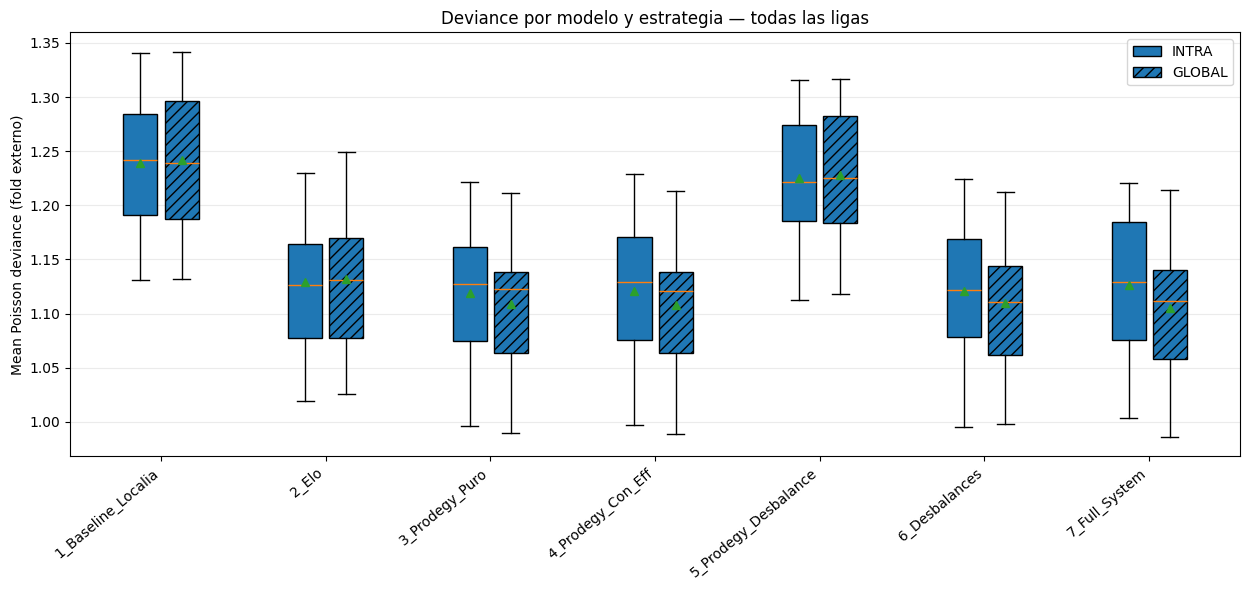

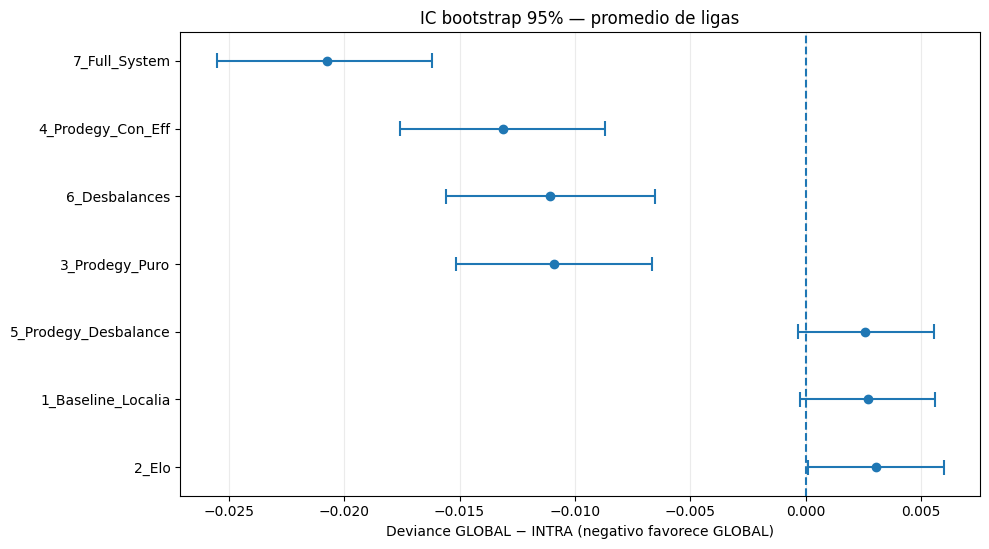

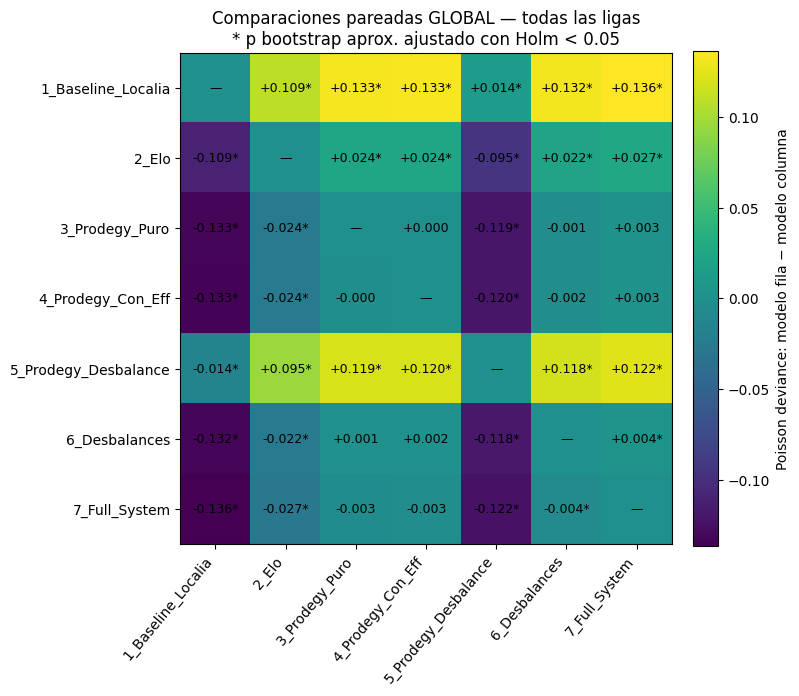

{'boxplots': (<Figure size 1260x600 with 1 Axes>,
  <Axes: title={'center': 'Deviance por modelo y estrategia — todas las ligas'}, ylabel='Mean Poisson deviance (fold externo)'>),
 'intervalos': (<Figure size 1000x559 with 1 Axes>,
  <Axes: title={'center': 'IC bootstrap 95% — promedio de ligas'}, xlabel='Deviance GLOBAL − INTRA (negativo favorece GLOBAL)'>),
 'matriz': (<Figure size 805x735 with 2 Axes>,
  <Axes: title={'center': 'Comparaciones pareadas GLOBAL — todas las ligas\n* p bootstrap aprox. ajustado con Holm < 0.05'}>)}

In [21]:
graficar_analisis_general(
    resultados,
    bootstrap,
    comparaciones_modelos,
    estrategia_matriz="GLOBAL"
)

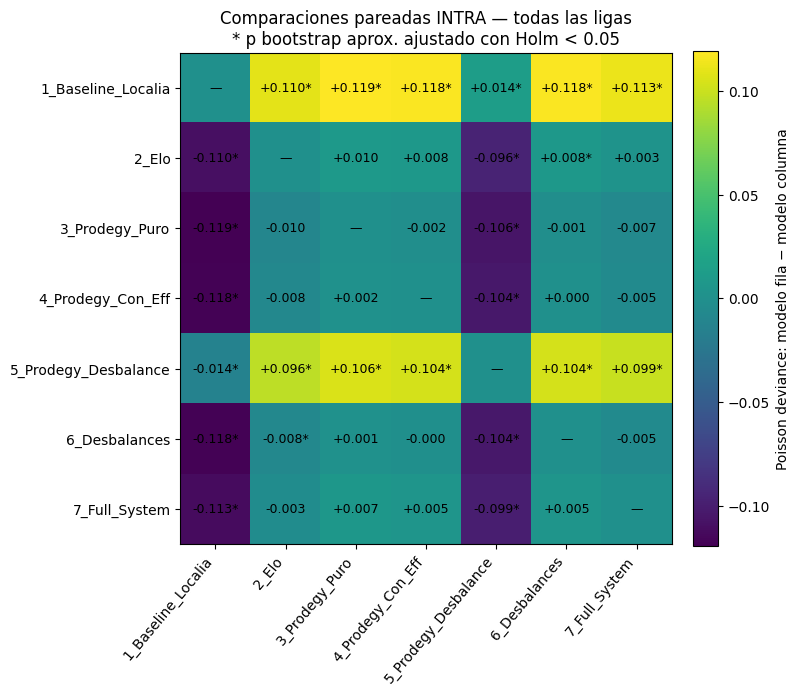

(<Figure size 805x735 with 2 Axes>,
 <Axes: title={'center': 'Comparaciones pareadas INTRA — todas las ligas\n* p bootstrap aprox. ajustado con Holm < 0.05'}>)

In [22]:
graficar_matriz_modelos(
    comparaciones_modelos,
    estrategia="INTRA"
)

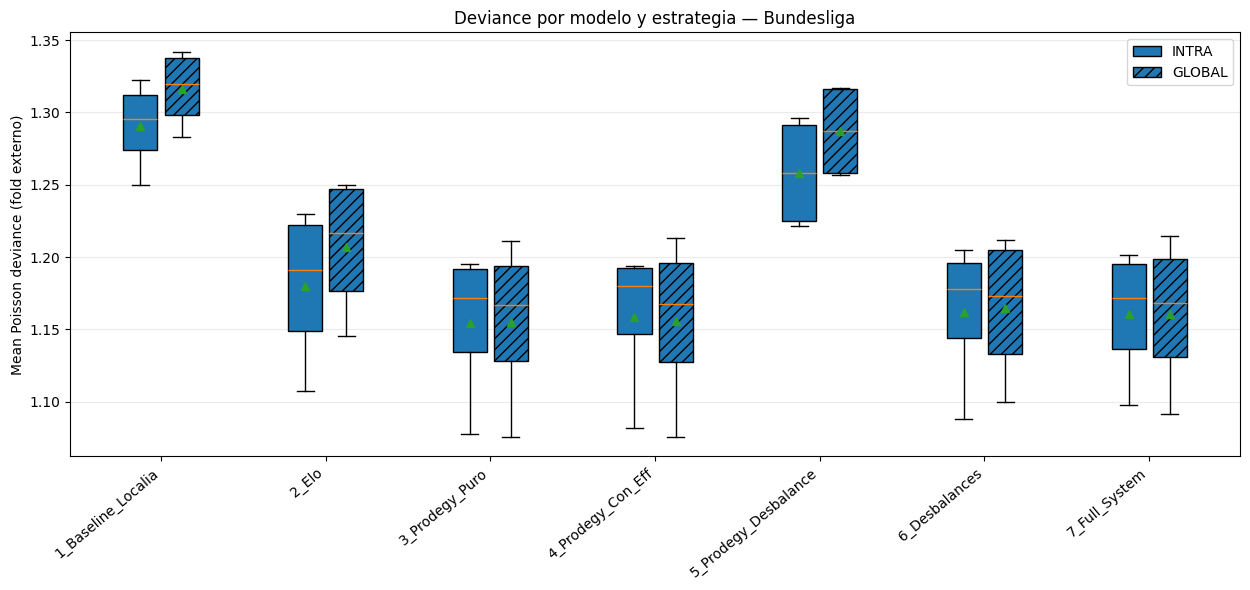

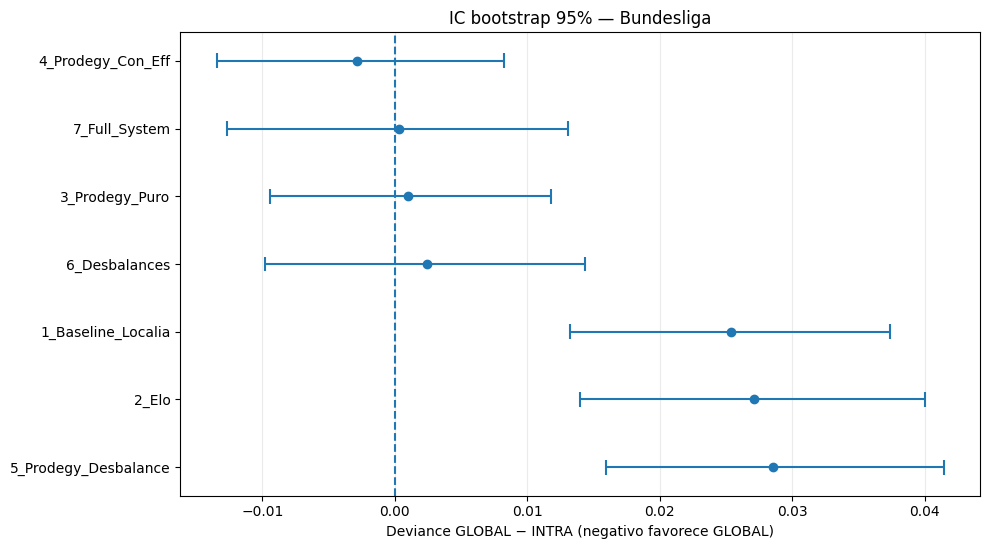

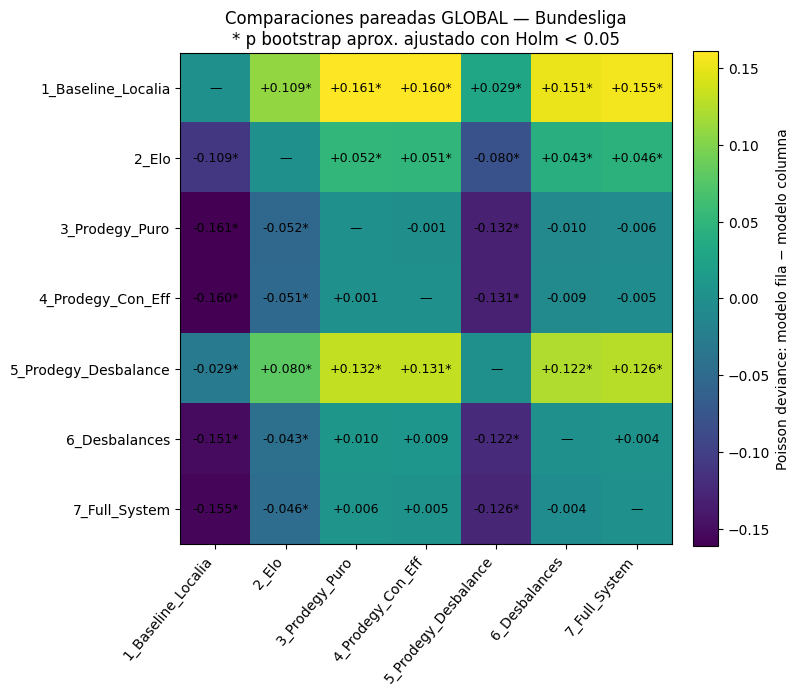

{'boxplots': (<Figure size 1260x600 with 1 Axes>,
  <Axes: title={'center': 'Deviance por modelo y estrategia — Bundesliga'}, ylabel='Mean Poisson deviance (fold externo)'>),
 'intervalos': (<Figure size 1000x559 with 1 Axes>,
  <Axes: title={'center': 'IC bootstrap 95% — Bundesliga'}, xlabel='Deviance GLOBAL − INTRA (negativo favorece GLOBAL)'>),
 'matriz': (<Figure size 805x735 with 2 Axes>,
  <Axes: title={'center': 'Comparaciones pareadas GLOBAL — Bundesliga\n* p bootstrap aprox. ajustado con Holm < 0.05'}>)}

In [23]:
graficar_analisis_liga(
    resultados,
    bootstrap,
    comparaciones_modelos,
    liga="Bundesliga",
    estrategia_matriz="GLOBAL"
)

In [24]:
display(
    comparaciones_modelos["por_liga"].query(
        "Liga == 'Bundesliga'"
    )
)

,Liga,Estrategia,N_Temporadas,Modelo_A,Modelo_B,Diferencia_A_menos_B,IC_inf,IC_sup,p_boot_aprox,p_Holm,Significativa_Holm_0.05
0,Bundesliga,GLOBAL,4,1_Baseline_Localia,2_Elo,0.108990,0.080851,0.139589,0.000500,0.020990,True
1,Bundesliga,GLOBAL,4,1_Baseline_Localia,3_Prodegy_Puro,0.161011,0.128688,0.195245,0.000500,0.020990,True
2,Bundesliga,GLOBAL,4,1_Baseline_Localia,4_Prodegy_Con_Eff,0.160053,0.127612,0.193885,0.000500,0.020990,True
3,Bundesliga,GLOBAL,4,1_Baseline_Localia,5_Prodegy_Desbalance,0.029186,0.021738,0.037554,0.000500,0.020990,True
4,Bundesliga,GLOBAL,4,1_Baseline_Localia,6_Desbalances,0.151491,0.120804,0.183966,0.000500,0.020990,True
5,Bundesliga,GLOBAL,4,1_Baseline_Localia,7_Full_System,0.155316,0.124040,0.189126,0.000500,0.020990,True
6,Bundesliga,GLOBAL,4,2_Elo,3_Prodegy_Puro,0.052021,0.031425,0.072887,0.000500,0.020990,True
7,Bundesliga,GLOBAL,4,2_Elo,4_Prodegy_Con_Eff,0.051063,0.030774,0.071822,0.000500,0.020990,True
8,Bundesliga,GLOBAL,4,2_Elo,5_Prodegy_Desbalance,-0.079804,-0.107110,-0.053704,0.000500,0.020990,True
9,Bundesliga,GLOBAL,4,2_Elo,6_Desbalances,0.042501,0.029755,0.055349,0.000500,0.020990,True


In [25]:
display(
    comparaciones_modelos["resumen"].sort_values(
        ["Estrategia", "p_Holm"]
    )
)

,Estrategia,N_Ligas,Modelo_A,Modelo_B,Diferencia_A_menos_B,IC_inf,IC_sup,p_boot_aprox,p_Holm,Significativa_Holm_0.05
0,GLOBAL,6,1_Baseline_Localia,2_Elo,0.109285,0.098673,0.120152,0.000500,0.020990,True
1,GLOBAL,6,1_Baseline_Localia,3_Prodegy_Puro,0.132973,0.122389,0.144433,0.000500,0.020990,True
2,GLOBAL,6,1_Baseline_Localia,4_Prodegy_Con_Eff,0.133418,0.122869,0.144845,0.000500,0.020990,True
3,GLOBAL,6,1_Baseline_Localia,5_Prodegy_Desbalance,0.013793,0.011303,0.016300,0.000500,0.020990,True
4,GLOBAL,6,1_Baseline_Localia,6_Desbalances,0.131771,0.121034,0.143278,0.000500,0.020990,True
5,GLOBAL,6,1_Baseline_Localia,7_Full_System,0.136165,0.125483,0.147516,0.000500,0.020990,True
6,GLOBAL,6,2_Elo,3_Prodegy_Puro,0.023688,0.017066,0.030325,0.000500,0.020990,True
7,GLOBAL,6,2_Elo,4_Prodegy_Con_Eff,0.024133,0.017632,0.030586,0.000500,0.020990,True
8,GLOBAL,6,2_Elo,5_Prodegy_Desbalance,-0.095492,-0.105885,-0.084983,0.000500,0.020990,True
9,GLOBAL,6,2_Elo,6_Desbalances,0.022485,0.017832,0.026844,0.000500,0.020990,True
